# Zonation Maps


<b> Objective: </b>
Map metal concentrations and ratios across Pierpaolo's East Greenland area with ML, and benchmark
it against kriging

----------------------

<i><b>Author: </b> Salvador Palma <br>
<b>Institution: </b> Copenhagen University </i>

A zonation map predicts concentrations where no samples exist, so own chemistry is never available. It is very illusive to RQ2 in that sense. Only inputs that exist everywhere can be used: position, geophysics, and the nearest samples.

Steps: prepare the data → spatial folds → compare methods (kriging, IDW, HGB with three feature sets)
→ fit the best on all samples and predict a grid.

### Imports

In [112]:
#Installs into whichever kernel runs the notebook; shapefile comes from pyshp
%pip install -q pykrige pyshp shapely openpyxl
#The GNN methods also need torch and torch_geometric, but only when their scores are not cached:
#%pip install -q torch torch_geometric

Note: you may need to restart the kernel to use updated packages.


In [113]:
import sys
import os
COLAB_SESSION = False

DRIVE_PATH = ""
if COLAB_SESSION:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    DRIVE_PATH = "/content/drive/MyDrive/UCPH/POOCS/"
    sys.path.insert(0, DRIVE_PATH)

import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapefile
import shapely
from shapely.geometry import shape
from joblib import Parallel, delayed
from pykrige.ok import OrdinaryKriging
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neighbors import NearestNeighbors

from GreenlandUtils import lonlatToUTM24N, PlotSamplesOnMap, Printable

pd.set_option("display.width", 200)

### Setup

In [114]:
SOURCE_XLSX = "Data/Zonation/greenland_portal.xlsx"
DATA_PATH = "Data/Zonation/"
RESULTS_PATH = "Results/Zonation/"
GEOPHYSICS_PATH = "Data/Geophysics/"
LAND_SHP = "Data/naturalearth/ne_land/ne_10m_land.shp"
os.makedirs(f"{DRIVE_PATH}{RESULTS_PATH}", exist_ok=True)

ELEMENTS = ["Cu", "Pb", "Zn", "Mo", "W", "Sb", "Ba", "Sr"]
RATIOS = [("Cu", "Pb"), ("Cu", "Zn"), ("Mo", "Pb"), ("Mo", "Sb"), ("W", "Pb"), ("W", "Sb"), ("Ba", "Sr")]

BLOCK_KM = 10 
N_FOLDS = 5
NEIGHBOUR_K = 10
GRID_KM = 1.0
MAX_DISTANCE_KM = 5.0
SEED = 42

### Data

In [115]:
CACHE_DATA = f"{DRIVE_PATH}{DATA_PATH}Data.csv"
TARGETS = [f"{e} ppm" for e in ELEMENTS] + [f"{a}/{b}" for a, b in RATIOS]


def Treat(raw: pd.DataFrame) -> pd.DataFrame:
    elementCols = [c for c in raw.columns if str(c).endswith(("ppm", "ppb", "wt%"))]
    df = raw.copy()

    for col in elementCols:
        values = df[col].astype(float)
        below = values < 0
        zero = values == 0
        values[below] = -values[below] / 2
      
        values[zero] = np.nan
        df[col] = values

    df = df.groupby("Sampleno", as_index=False).agg(
        { **{ c: "first" for c in ["Longitude", "Latitude", "Batch"] }, **{ c: "median" for c in elementCols } })
    df[elementCols] = np.log10(df[elementCols].where(df[elementCols] > 0))

    for a, b in RATIOS:
        df[f"{a}/{b}"] = df[f"{a} ppm"] - df[f"{b} ppm"]
    return df


if os.path.exists(CACHE_DATA):
    df = pd.read_csv(CACHE_DATA, delimiter=";")
    print("Loaded cached data")
else:
    raw = pd.read_excel(f"{DRIVE_PATH}{SOURCE_XLSX}")
    df = Treat(raw)
    df.to_csv(CACHE_DATA, sep=";", index=False)
    print(f"Treated {len(raw)} rows")

x, y = lonlatToUTM24N(df["Longitude"].to_numpy(float), df["Latitude"].to_numpy(float))
df["x_km"], df["y_km"] = x / 1000, y / 1000

printable = Printable()
printable.title(f"{len(df)} samples at {df[['x_km', 'y_km']].drop_duplicates().shape[0]} locations")
for target in TARGETS:
    printable.add(target, f"{df[target].notna().sum():>5} values")
printable.flush()

Loaded cached data
===== 4000 samples at 1668 locations =====
Cu ppm:       3592 values
Pb ppm:       3152 values
Zn ppm:       2981 values
Mo ppm:       1938 values
W ppm:        1895 values
Sb ppm:       1388 values
Ba ppm:       2525 values
Sr ppm:        873 values
Cu/Pb:        3028 values
Cu/Zn:        2876 values
Mo/Pb:        1842 values
Mo/Sb:        1332 values
W/Pb:         1794 values
W/Sb:         1331 values
Ba/Sr:         493 values


### Geophysics

Same three grids as the main pipeline, sampled at each point. Downloaded from GEUS Dataverse into
`Data/Geophysics/` if missing.

In [116]:
GEOPHYSICS_FILES = {
    "GREENMAG_magnetic_anomaly.hdr": 91477,
    "GREENMAG_magnetic_anomaly.flt": 91476,
    "GeothermalHeatFlow.xyz": 19155,
    "DepthToMoho.xyz": 32409,
}
GEO_COLS = ["geo_magnetic nT", "geo_heat_flow mW/m2", "geo_moho km"]

os.makedirs(f"{DRIVE_PATH}{GEOPHYSICS_PATH}", exist_ok=True)
for name, fileId in GEOPHYSICS_FILES.items():
    path = f"{DRIVE_PATH}{GEOPHYSICS_PATH}{name}"
    if not os.path.exists(path):
        import urllib.request
        print(f"downloading {name}...")
        urllib.request.urlretrieve(f"https://dataverse.geus.dk/api/access/datafile/{fileId}", path)


def SampleESRIGrid(points: pd.DataFrame, baseName: str) -> np.ndarray:
    with open(f"{DRIVE_PATH}{GEOPHYSICS_PATH}{baseName}.hdr") as f:
        header = { k.lower(): v for k, v in (line.split() for line in f if line.strip()) }
    header = { k: float(v) if v.lstrip("-").replace(".", "", 1).isdigit() else v for k, v in header.items() }
    ncols, nrows, cell = int(header["ncols"]), int(header["nrows"]), header["cellsize"]
    grid = np.memmap(f"{DRIVE_PATH}{GEOPHYSICS_PATH}{baseName}.flt", dtype="<f4", mode="r", shape=(nrows, ncols))

    x, y = lonlatToUTM24N(points["Longitude"].to_numpy(float), points["Latitude"].to_numpy(float))
    col = np.floor((x - header["xllcorner"]) / cell).astype(int)
    row = np.floor((header["yllcorner"] + nrows * cell - y) / cell).astype(int)
    inside = (col >= 0) & (col < ncols) & (row >= 0) & (row < nrows)

    values = np.full(len(points), np.nan)
    values[inside] = grid[row[inside], col[inside]]
    values[values == header["nodata_value"]] = np.nan
    return values


_xyzCache = {}
def SampleXYZGrid(points: pd.DataFrame, fileName: str) -> np.ndarray:
    if fileName not in _xyzCache:
        grid = pd.read_csv(f"{DRIVE_PATH}{GEOPHYSICS_PATH}{fileName}", sep=r"\s+", comment="%", header=None,
                           usecols=[0, 1, 2]).to_numpy(float)
        _xyzCache[fileName] = (NearestNeighbors(n_neighbors=1).fit(grid[:, :2]), grid[:, 2])
    tree, values = _xyzCache[fileName]
    _, positions = tree.kneighbors(points[["Longitude", "Latitude"]].to_numpy(float))
    return values[positions[:, 0]]


def AddGeophysics(points: pd.DataFrame) -> pd.DataFrame:
    points = points.copy()
    points[GEO_COLS[0]] = SampleESRIGrid(points, "GREENMAG_magnetic_anomaly")
    points[GEO_COLS[1]] = SampleXYZGrid(points, "GeothermalHeatFlow.xyz")
    points[GEO_COLS[2]] = SampleXYZGrid(points, "DepthToMoho.xyz")
    return points


df = AddGeophysics(df)
display(df[GEO_COLS].describe().loc[["count", "min", "max"]].round(1))

,geo_magnetic nT,geo_heat_flow mW/m2,geo_moho km
count,4000.0,4000.0,4000.0
min,-243.8,46.4,20.8
max,1067.2,69.5,26.1


### Fold Creation

In [117]:
def SpatialFolds(frame: pd.DataFrame, blockKm: float = BLOCK_KM, nFolds: int = N_FOLDS) -> np.ndarray:
    block = (np.floor(frame["x_km"] / blockKm).astype(int).astype(str) + "_"
             + np.floor(frame["y_km"] / blockKm).astype(int).astype(str))
    sizes = block.value_counts().sample(frac=1, random_state=SEED).sort_values(ascending=False, kind="stable")
    load, assignment = np.zeros(nFolds), {}
    for name, size in sizes.items():
        fold = int(np.argmin(load))
        assignment[name] = fold
        load[fold] += size
    return block.map(assignment).to_numpy(), block.to_numpy()


df["fold_spatial"], df["block"] = SpatialFolds(df)
df["fold_random"] = np.random.default_rng(SEED).integers(0, N_FOLDS, len(df))


def NearestTrainingKm(foldCol: str) -> np.ndarray:
    xy = df[["x_km", "y_km"]].to_numpy()
    out = np.zeros(len(df))
    for fold in range(N_FOLDS):
        test = df[foldCol].to_numpy() == fold
        tree = NearestNeighbors(n_neighbors=1).fit(xy[~test])
        out[test] = tree.kneighbors(xy[test])[0][:, 0]
    return out


printable = Printable()
printable.title("Folds")
printable.add("spatial fold sizes", str(np.bincount(df["fold_spatial"]).tolist()))
for mode in ["spatial", "random"]:
    printable.add(f"{mode}: median km to nearest training sample", f"{np.median(NearestTrainingKm(f'fold_{mode}')):.2f}")
printable.flush()

============================== Folds ==============================
spatial fold sizes:                              [800, 800, 800, 800, 800]
spatial: median km to nearest training sample:   2.79
random: median km to nearest training sample:    0.00


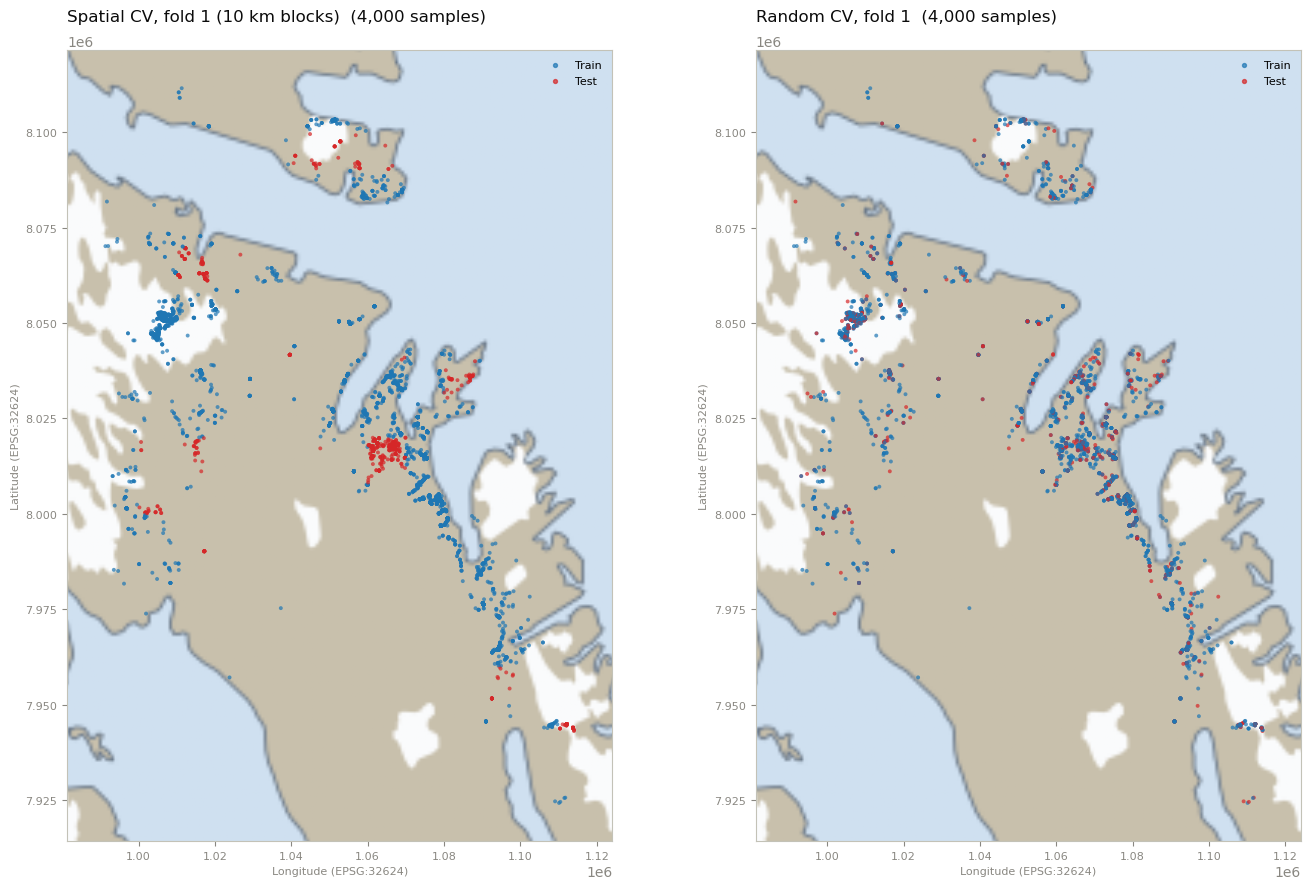

In [118]:
def DisplayFold(foldCol: str, fold: int, ax, title: str):
    frame = df.copy()
    frame["colors"] = np.where(frame[foldCol] == fold, "#d62728", "#1f77b4")
    PlotSamplesOnMap(frame, colorCol="colors", title=title, ax=ax, pointSize=8,
                     colorLabels={ "Train": "#1f77b4", "Test": "#d62728" })
    ax.set_xlim(frame["x_km"].min() * 1000 - 10_000, frame["x_km"].max() * 1000 + 10_000)
    ax.set_ylim(frame["y_km"].min() * 1000 - 10_000, frame["y_km"].max() * 1000 + 10_000)


fig, axes = plt.subplots(1, 2, figsize=(14, 9))
DisplayFold("fold_spatial", 0, axes[0], f"Spatial CV, fold 1 ({BLOCK_KM} km blocks)")
DisplayFold("fold_random", 0, axes[1], "Random CV, fold 1")
plt.tight_layout()
plt.show()

### Feature Sets

| set | features |
|---|---|
| `Coordinates` | easting, northing |
| `Coordinates + Geophysics` | plus magnetic anomaly, heat flow, Moho depth |
| `Coordinates + Geophysics + Neighbours` | plus IDW mean of the target over its `NEIGHBOUR_K` nearest samples, distance to the nearest one, and the neighbour mean of every target element |
| `Coordinates + Geophysics + KNN C` | coordinates, geophysics, and KNN C |

Samples from own block are excluded from KNN integrations

In [119]:
def NeighbourStats(source: pd.DataFrame, value: str, query: pd.DataFrame, exclude: str) -> pd.DataFrame:
    source = source[source[value].notna()]
    out = pd.DataFrame(np.nan, index=query.index, columns=["idw", "mean", "dist"])
    if len(source) < 2:
        return out

    groups = query.groupby("block") if exclude == "block" else [(None, query)]
    for block, part in groups:
        pool = source[source["block"] != block] if exclude == "block" else source
        k = min(NEIGHBOUR_K + (20 if exclude == "location" else 0), len(pool))
        if k == 0:
            continue
        dist, pos = NearestNeighbors(n_neighbors=k).fit(pool[["x_km", "y_km"]]).kneighbors(part[["x_km", "y_km"]])
        vals = pool[value].to_numpy()[pos]
        if exclude == "location":
            dist = np.where(dist < 1e-6, np.inf, dist)
            order = np.argsort(dist, axis=1)[:, :NEIGHBOUR_K]
            dist, vals = np.take_along_axis(dist, order, 1), np.take_along_axis(vals, order, 1)
        usable = np.isfinite(dist)
        weights = np.where(usable, 1 / np.maximum(dist, 0.05) ** 2, 0)
        vals = np.where(usable, vals, 0)
        out.loc[part.index, "idw"] = (weights * vals).sum(1) / np.maximum(weights.sum(1), 1e-12)
        out.loc[part.index, "mean"] = vals.sum(1) / np.maximum(usable.sum(1), 1)
        out.loc[part.index, "dist"] = np.where(usable, dist, np.inf).min(1)
    return out


NEIGHBOURS_SET = "Coordinates + Geophysics + Neighbours"
ALL_SET = "Coordinates + Geophysics + KNN C"
MIN_NEIGHBOUR_COVERAGE = 10
ALL_NEIGHBOUR_ELEMENTS = [c for c in df.columns if str(c).endswith(("ppm", "ppb", "wt%")) and df[c].notna().sum() >= MIN_NEIGHBOUR_COVERAGE]
COLOCATION_PAD = int(df.groupby(["x_km", "y_km"]).size().max())


def AllNeighbourMeans(source: pd.DataFrame, query: pd.DataFrame, exclude: str) -> pd.DataFrame:
    values = source[ALL_NEIGHBOUR_ELEMENTS].to_numpy(float)
    out = np.full((len(query), len(ALL_NEIGHBOUR_ELEMENTS)), np.nan)
    rows = pd.Series(np.arange(len(query)), index=query.index)

    groups = query.groupby("block") if exclude == "block" else [(None, query)]
    for block, part in groups:
        keep = (source["block"] != block).to_numpy() if exclude == "block" else np.ones(len(source), bool)
        pool = source[keep]
        k = min(NEIGHBOUR_K + (COLOCATION_PAD if exclude == "location" else 0), len(pool))
        if k == 0:
            continue
        dist, pos = NearestNeighbors(n_neighbors=k).fit(pool[["x_km", "y_km"]]).kneighbors(part[["x_km", "y_km"]])
        if exclude == "location":
            #Drop same-location samples (including itself), then keep the k nearest remaining
            dist = np.where(dist < 1e-6, np.inf, dist)
            order = np.argsort(dist, axis=1)[:, :NEIGHBOUR_K]
            dist, pos = np.take_along_axis(dist, order, 1), np.take_along_axis(pos, order, 1)
        neighbourValues = values[keep][pos]                       # (points, k, elements)
        neighbourValues[~np.isfinite(dist)] = np.nan
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            out[rows.loc[part.index].to_numpy()] = np.nanmean(neighbourValues, axis=1)

    return pd.DataFrame(out, index=query.index, columns=[f"knnc_{e}" for e in ALL_NEIGHBOUR_ELEMENTS])


def BuildFeatures(train: pd.DataFrame, query: pd.DataFrame, target: str, featureSet: str, exclude: str,
                  allNeighbours: pd.DataFrame = None) -> pd.DataFrame:
    X = query[["x_km", "y_km"]].copy()
    if featureSet != "Coordinates":
        X[GEO_COLS] = query[GEO_COLS]
    if featureSet == NEIGHBOURS_SET:
        stats = NeighbourStats(train, target, query, exclude)
        X["nb_idw"], X["nb_dist"] = stats["idw"], stats["dist"]
    if featureSet == NEIGHBOURS_SET:
        for element in ELEMENTS:
            X[f"nb_mean_{element}"] = NeighbourStats(train, f"{element} ppm", query, exclude)["mean"]
    if featureSet == ALL_SET:
        X = X.join(allNeighbours.loc[query.index])
    return X


print(f"KNN C set: {len(ALL_NEIGHBOUR_ELEMENTS)} elements with >= {MIN_NEIGHBOUR_COVERAGE} values, k = {NEIGHBOUR_K}")

KNN C set: 55 elements with >= 10 values, k = 10


### Methods

| method | idea |
|---|---|
| `IDW` | inverse-distance mean of the nearest training samples |
| `Kriging` | Standard for geostats |
| `HGB <set>` | gradient boosting on one of the feature sets |
| `GNN SAGE` / `GNN GAT` | graph network over the nearest training samples; GAT also reads the distance |

Since kriging needs one value per location, co-located samples are merged by mean first.

In [120]:
FEATURE_SETS = ["Coordinates", "Coordinates + Geophysics", NEIGHBOURS_SET, ALL_SET]
GNN_METHODS = ["GNN SAGE", "GNN GAT"]
METHODS = ["IDW", "Kriging"] + [f"HGB {s}" for s in FEATURE_SETS] + GNN_METHODS


def Kriging(train: pd.DataFrame, query: pd.DataFrame, target: str) -> np.ndarray:
    points = train[["x_km", "y_km", target]].dropna().groupby(["x_km", "y_km"], as_index=False)[target].mean()
    if len(points) < 10:
        return np.full(len(query), np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = OrdinaryKriging(points["x_km"], points["y_km"], points[target],
                                variogram_model="spherical", nlags=12, pseudo_inv=True)
        #Chunked so a large map grid does not build one huge distance matrix
        chunks = [model.execute("points", query["x_km"].to_numpy()[idx], query["y_km"].to_numpy()[idx])[0]
                  for idx in np.array_split(np.arange(len(query)), max(1, len(query) // 4000))]
    return np.concatenate([np.asarray(c) for c in chunks])


def Predict(method: str, train: pd.DataFrame, query: pd.DataFrame, target: str, exclude: str,
            allNeighbours: tuple = (None, None)) -> np.ndarray:
    train = train[train[target].notna()]
    
    queryExclude = "location" if exclude == "location" else "none"
    if method == "IDW":
        return NeighbourStats(train, target, query, queryExclude)["idw"].to_numpy()
    if method == "Kriging":
        return Kriging(train, query, target)

    featureSet = method.replace("HGB ", "")
    trainExclude = "location" if exclude == "location" else "block"
    Xtrain = BuildFeatures(train, train, target, featureSet, trainExclude, allNeighbours[0])
    Xquery = BuildFeatures(train, query, target, featureSet, queryExclude, allNeighbours[1])
    
    usable = [c for c in Xtrain.columns if Xtrain[c].nunique(dropna=True) >= 2]
    model = HistGradientBoostingRegressor(max_iter=200, random_state=SEED).fit(Xtrain[usable], train[target])
    return model.predict(Xquery[usable])


def RunWithProgress(function, jobs: list, label: str) -> list:
    results, step, start = [], max(1, len(jobs) // 10), time.time()
    for done, result in enumerate(Parallel(n_jobs=-1, return_as="generator")(delayed(function)(*job) for job in jobs), 1):
        results.append(result)
        if done % step == 0 or done == len(jobs):
            print(f"   {label}: {done}/{len(jobs)}  ({time.time() - start:.0f} s)", flush=True)
    return results

### Graph Network

The same neighbourhood as the other methods, but the aggregation is learned:

* **Nodes** are samples and the points to predict. **Edges** come from each point's `NEIGHBOUR_K`
  nearest training samples, with the same exclusions as HGB (own block, or own location under random CV).
* **Neighbours send** their full chemistry, target included, as in KNN C.
* **A point knows about itself** only its coordinates and geophysics, since a map point has no chemistry.
* **One bipartite layer.** A second hop would let a training sample's own value return to it.

`GNN GAT` reads the distance on each edge; `GNN SAGE` does not. Early stopping on a validation slice of
the training nodes, with a generous patience. torch is only imported when a GNN actually has to train.

In [121]:
GNN_HIDDEN = 64
GNN_LR = 0.01
GNN_MAX_EPOCHS = 2000
GNN_PATIENCE = 150


def NeighbourIndex(source: pd.DataFrame, query: pd.DataFrame, exclude: str) -> tuple[np.ndarray, np.ndarray]:
    """Row positions in `source`, and distances, of each query point's k nearest usable sources."""
    pos = np.zeros((len(query), NEIGHBOUR_K), dtype=int)
    dist = np.full((len(query), NEIGHBOUR_K), np.inf)
    rows = pd.Series(np.arange(len(query)), index=query.index)

    groups = query.groupby("block") if exclude == "block" else [(None, query)]
    for block, part in groups:
        keep = np.flatnonzero((source["block"] != block).to_numpy()) if exclude == "block" else np.arange(len(source))
        k = min(NEIGHBOUR_K + (COLOCATION_PAD if exclude == "location" else 0), len(keep))
        if k == 0:
            continue
        d, p = NearestNeighbors(n_neighbors=k).fit(source.iloc[keep][["x_km", "y_km"]]).kneighbors(part[["x_km", "y_km"]])
        if exclude == "location":
            d = np.where(d < 1e-6, np.inf, d)
        order = np.argsort(d, axis=1)[:, :NEIGHBOUR_K]
        d, p = np.take_along_axis(d, order, 1), np.take_along_axis(p, order, 1)
        r = rows.loc[part.index].to_numpy()
        pos[r, :d.shape[1]], dist[r, :d.shape[1]] = keep[p], d
    return pos, dist


def Scale(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Standardised values (zero where missing) and a present flag, per column."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        centre, spread = np.nanmean(values, axis=0), np.nanstd(values, axis=0)
    spread = np.where(~np.isfinite(spread) | (spread == 0), 1.0, spread)
    centre = np.where(np.isfinite(centre), centre, 0.0)
    present = np.isfinite(values).astype(np.float32)
    return np.where(np.isfinite(values), (values - centre) / spread, 0.0).astype(np.float32), present


def PredictGNN(sources: pd.DataFrame, query: pd.DataFrame, target: str, mode: str, layer: str) -> np.ndarray:
    """sources: every training sample of the fold, whatever it measured. query: the points to predict."""
    import torch
    import torch.nn as nn
    from torch_geometric.nn import GATConv, SAGEConv

    torch.set_num_threads(1)          # one per parallel job
    torch.manual_seed(SEED)

    labelled = sources[sources[target].notna()]
    nodes = pd.concat([labelled, query])
    trainExclude = "location" if mode == "random" else "block"
    queryExclude = "location" if mode == "random" else "none"

    posL, distL = NeighbourIndex(sources, labelled, trainExclude)
    posQ, distQ = NeighbourIndex(sources, query, queryExclude)
    src, dist = np.vstack([posL, posQ]).ravel(), np.vstack([distL, distQ]).ravel()
    dst = np.repeat(np.arange(len(nodes)), NEIGHBOUR_K)
    ok = np.isfinite(dist)
    edgeIndex = torch.tensor(np.vstack([src[ok], dst[ok]]), dtype=torch.long)
    edgeAttr = torch.tensor(np.log1p(dist[ok]), dtype=torch.float32).unsqueeze(1)

    chemistry, present = Scale(sources[ALL_NEIGHBOUR_ELEMENTS].to_numpy(float))
    xSrc = torch.tensor(np.hstack([chemistry, present]))
    xDst = torch.tensor(Scale(nodes[["x_km", "y_km"] + GEO_COLS].to_numpy(float))[0])

    y = labelled[target].to_numpy(float)
    mu, sd = y.mean(), (y.std() or 1.0)
    yT = torch.tensor((y - mu) / sd, dtype=torch.float32)

    class Net(nn.Module):
        def __init__(self):
            super().__init__()
            dims = (xSrc.shape[1], xDst.shape[1])
            self.conv = (GATConv(dims, GNN_HIDDEN // 4, heads=4, edge_dim=1, add_self_loops=False)
                         if layer == "gat" else SAGEConv(dims, GNN_HIDDEN))
            self.head = nn.Sequential(nn.Linear(GNN_HIDDEN + xDst.shape[1], GNN_HIDDEN), nn.ReLU(), nn.Linear(GNN_HIDDEN, 1))

        def forward(self):
            h = (self.conv((xSrc, xDst), edgeIndex, edge_attr=edgeAttr) if layer == "gat"
                 else self.conv((xSrc, xDst), edgeIndex))
            return self.head(torch.cat([torch.relu(h), xDst], dim=1)).squeeze(-1)

    model = Net()
    optimiser = torch.optim.Adam(model.parameters(), lr=GNN_LR, weight_decay=1e-4)
    order = np.random.default_rng(SEED).permutation(len(labelled))
    valid, fit = torch.tensor(order[: len(order) // 10]), torch.tensor(order[len(order) // 10:])

    best, bestState, waited = np.inf, None, 0
    for epoch in range(GNN_MAX_EPOCHS):
        model.train()
        optimiser.zero_grad()
        loss = ((model()[fit] - yT[fit]) ** 2).mean()
        loss.backward()
        optimiser.step()
        model.eval()
        with torch.no_grad():
            validLoss = float(((model()[valid] - yT[valid]) ** 2).mean())
        if validLoss < best - 1e-5:
            best, waited = validLoss, 0
            bestState = { k: v.clone() for k, v in model.state_dict().items() }
        else:
            waited += 1
            if waited >= GNN_PATIENCE:
                break

    model.load_state_dict(bestState)
    model.eval()
    with torch.no_grad():
        return model()[len(labelled):].numpy() * sd + mu

### Cross-Validation

Out-of-fold predictions for every target, method and fold scheme, scored once per target. Cached;
delete the file to rerun.

In [122]:
CACHE_SCORES = f"{DRIVE_PATH}{RESULTS_PATH}CV_Scores.csv"
MODES = ["spatial", "random"]


def FoldSplit(mode: str, fold: int):
    foldCol = f"fold_{mode}"
    return df[df[foldCol] != fold], df[df[foldCol] == fold]


def FoldNeighbourTables(mode: str, fold: int) -> tuple:
    train, test = FoldSplit(mode, fold)
    trainExclude = "location" if mode == "random" else "block"
    queryExclude = "location" if mode == "random" else "none"
    return (mode, fold), (AllNeighbourMeans(train, train, trainExclude), AllNeighbourMeans(train, test, queryExclude))


def CVJob(target: str, method: str, mode: str, fold: int, allNeighbours: tuple = (None, None)) -> pd.DataFrame:
    train, test = FoldSplit(mode, fold)
    test = test[test[target].notna()]
    if test.empty:
        return pd.DataFrame()
    if method in GNN_METHODS:
        #The graph takes every training sample as a source, whatever it measured
        prediction = PredictGNN(train, test, target, mode, method.split()[-1].lower())
    else:
        exclude = "block" if mode == "spatial" else "location"
        prediction = Predict(method, train[train[target].notna()], test, target, exclude, allNeighbours)
    return pd.DataFrame({ "target": target, "method": method, "mode": mode, "sample": test.index,
                          "prediction": prediction })


def Score(frame: pd.DataFrame, target: str) -> pd.Series:
    frame = frame.dropna(subset=["prediction"])
    truth = df.loc[frame["sample"], target].to_numpy()
    guess = frame["prediction"].to_numpy()
    return pd.Series({ "r2": 1 - ((truth - guess) ** 2).sum() / ((truth - truth.mean()) ** 2).sum(),
                       "mae": np.abs(truth - guess).mean(), "n": len(frame) })

scores = pd.read_csv(CACHE_SCORES, delimiter=";") if os.path.exists(CACHE_SCORES) else pd.DataFrame(columns=["method"])
missing = [m for m in METHODS if m not in set(scores["method"])]
print(f"Cached: {len(scores)} scores. To run: {missing if missing else 'nothing'}")

if missing:
    tables = {}
    if f"HGB {ALL_SET}" in missing:
        print("Precomputing all-element neighbour tables...")
        folds = [(mode, fold) for mode in MODES for fold in range(N_FOLDS)]
        tables = dict(RunWithProgress(FoldNeighbourTables, folds, "neighbour tables"))

    jobs = [(t, m, mode, f, tables.get((mode, f), (None, None)) if m == f"HGB {ALL_SET}" else (None, None))
            for t in TARGETS for m in missing for mode in MODES for f in range(N_FOLDS)]
    print(f"Running {len(jobs)} CV jobs...")
    predictions = pd.concat(RunWithProgress(CVJob, jobs, "CV jobs"))
    new = pd.DataFrame([{ "target": t, "method": m, "mode": mode, **Score(group, t) }
                        for (t, m, mode), group in predictions.groupby(["target", "method", "mode"])])
    scores = pd.concat([scores, new], ignore_index=True)
    scores.to_csv(CACHE_SCORES, sep=";", index=False)
    print(f"Saved {len(scores)} scores")

Cached: 240 scores. To run: nothing


### Results

In [123]:
summary = scores.pivot_table(index="method", columns="mode", values="r2", aggfunc="mean").reindex(METHODS)
summary["optimism"] = summary["random"] - summary["spatial"]
print("Mean R2 over targets (log10 scale)")
display(summary.round(3))

perTarget = scores[scores["mode"] == "spatial"].pivot_table(index="target", columns="method", values="r2")[METHODS].reindex(TARGETS)
perTarget["best"] = perTarget.idxmax(axis=1)
print("Spatial CV, per target")
display(perTarget.round(3))

Mean R2 over targets (log10 scale)


mode,random,spatial,optimism
method,,,
IDW,0.139,0.031,0.107
Kriging,0.410,0.095,0.315
HGB Coordinates,0.406,-0.113,0.519
HGB Coordinates + Geophysics,0.413,-0.087,0.500
HGB Coordinates + Geophysics + Neighbours,0.396,-0.006,0.403
HGB Coordinates + Geophysics + KNN C,0.371,-0.024,0.395
GNN SAGE,0.328,-0.345,0.673
GNN GAT,0.355,-0.234,0.589


Spatial CV, per target


method,IDW,Kriging,HGB Coordinates,HGB Coordinates + Geophysics,HGB Coordinates + Geophysics + Neighbours,HGB Coordinates + Geophysics + KNN C,GNN SAGE,GNN GAT,best
target,,,,,,,,,
Cu ppm,-0.039,0.017,-0.168,-0.099,-0.060,0.023,-1.013,-0.115,HGB Coordinates + Geophysics + KNN C
Pb ppm,-0.081,-0.000,-0.083,-0.107,0.026,-0.085,-0.685,-0.267,HGB Coordinates + Geophysics + Neighbours
Zn ppm,-0.227,-0.031,-0.537,-0.604,-0.199,-0.428,-0.225,-0.534,Kriging
Mo ppm,0.047,0.162,-0.027,0.034,0.019,0.021,-0.497,-0.354,Kriging
W ppm,0.206,0.137,0.045,0.077,0.126,0.147,-0.373,-0.177,IDW
Sb ppm,-0.100,0.013,-0.204,-0.177,-0.247,-0.189,-0.236,-0.224,Kriging
Ba ppm,-0.306,-0.029,-0.503,-0.351,-0.183,-0.159,-0.603,-0.588,Kriging
Sr ppm,0.638,0.626,0.265,0.401,0.572,0.555,0.689,0.530,GNN SAGE
Cu/Pb,-0.145,-0.121,-0.249,-0.305,-0.192,-0.139,-0.834,-0.740,Kriging


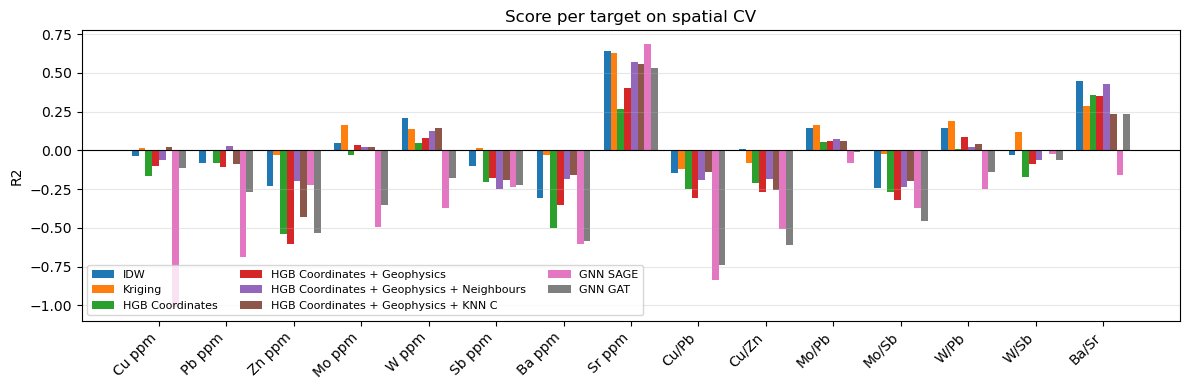

In [127]:
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(TARGETS))
width = 0.8 / len(METHODS)
for i, method in enumerate(METHODS):
    ax.bar(x + (i - (len(METHODS) - 1) / 2) * width, perTarget[method], width, label=method)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, TARGETS, rotation=45, ha="right")
ax.set_ylabel("R2")
ax.set_title("Score per target on spatial CV")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

### Map

In [125]:
CACHE_GRID = f"{DRIVE_PATH}{RESULTS_PATH}Grid_Predictions.csv"
CACHE_GRID_METHODS = f"{DRIVE_PATH}{RESULTS_PATH}Grid_Methods.json"


def BuildGrid() -> pd.DataFrame:
    latStep = GRID_KM / 111.0
    lonStep = GRID_KM / (111.0 * np.cos(np.radians(df["Latitude"].mean())))
    lons = np.arange(df["Longitude"].min() - 0.1, df["Longitude"].max() + 0.1, lonStep)
    lats = np.arange(df["Latitude"].min() - 0.05, df["Latitude"].max() + 0.05, latStep)
    grid = pd.DataFrame([(lo, la) for la in lats for lo in lons], columns=["Longitude", "Latitude"])

    #Land only, using the Natural Earth outline already in Data/
    reader = shapefile.Reader(shp=open(f"{DRIVE_PATH}{LAND_SHP}", "rb"))
    box = shapely.box(lons.min(), lats.min(), lons.max(), lats.max())
    land = shapely.union_all([shapely.make_valid(shape(s.__geo_interface__)).intersection(box) for s in reader.shapes()
                              if shapely.box(*s.bbox).intersects(box)])
    grid = grid[shapely.contains_xy(land, grid["Longitude"], grid["Latitude"])].reset_index(drop=True)

    x, y = lonlatToUTM24N(grid["Longitude"].to_numpy(), grid["Latitude"].to_numpy())
    grid["x_km"], grid["y_km"] = x / 1000, y / 1000
    grid["block"] = "grid"
    return AddGeophysics(grid)


#Incremental: a target is re-mapped only when its best HGB feature set changed
grid = pd.read_csv(CACHE_GRID, delimiter=";") if os.path.exists(CACHE_GRID) else BuildGrid()
mapped = json.load(open(CACHE_GRID_METHODS)) if os.path.exists(CACHE_GRID_METHODS) else {}
gridTables = None

for target in TARGETS:
    method = perTarget.loc[target, [f"HGB {s}" for s in FEATURE_SETS]].idxmax()
    if mapped.get(target) == method and target in grid:
        continue

    if method == f"HGB {ALL_SET}" and gridTables is None:
        print("Precomputing all-element neighbour tables for the grid...", flush=True)
        gridTables = (AllNeighbourMeans(df, df, "block"), AllNeighbourMeans(df, grid, "none"))

    start = time.time()
    grid[target] = Predict(method, df, grid, target, "none", gridTables if method == f"HGB {ALL_SET}" else (None, None))
    if f"{target} kriging" not in grid:
        grid[f"{target} kriging"] = Predict("Kriging", df, grid, target, "none")
    measured = df[df[target].notna()]
    grid[f"{target} dist_km"] = NearestNeighbors(n_neighbors=1).fit(measured[["x_km", "y_km"]]).kneighbors(grid[["x_km", "y_km"]])[0][:, 0]
    mapped[target] = method
    print(f"{target:8} mapped with {method}  ({time.time() - start:.0f} s)", flush=True)

grid.to_csv(CACHE_GRID, sep=";", index=False)
json.dump(mapped, open(CACHE_GRID_METHODS, "w"), indent=2)
print(f"{len(grid)} land cells at {GRID_KM} km")

17004 land cells at 1.0 km


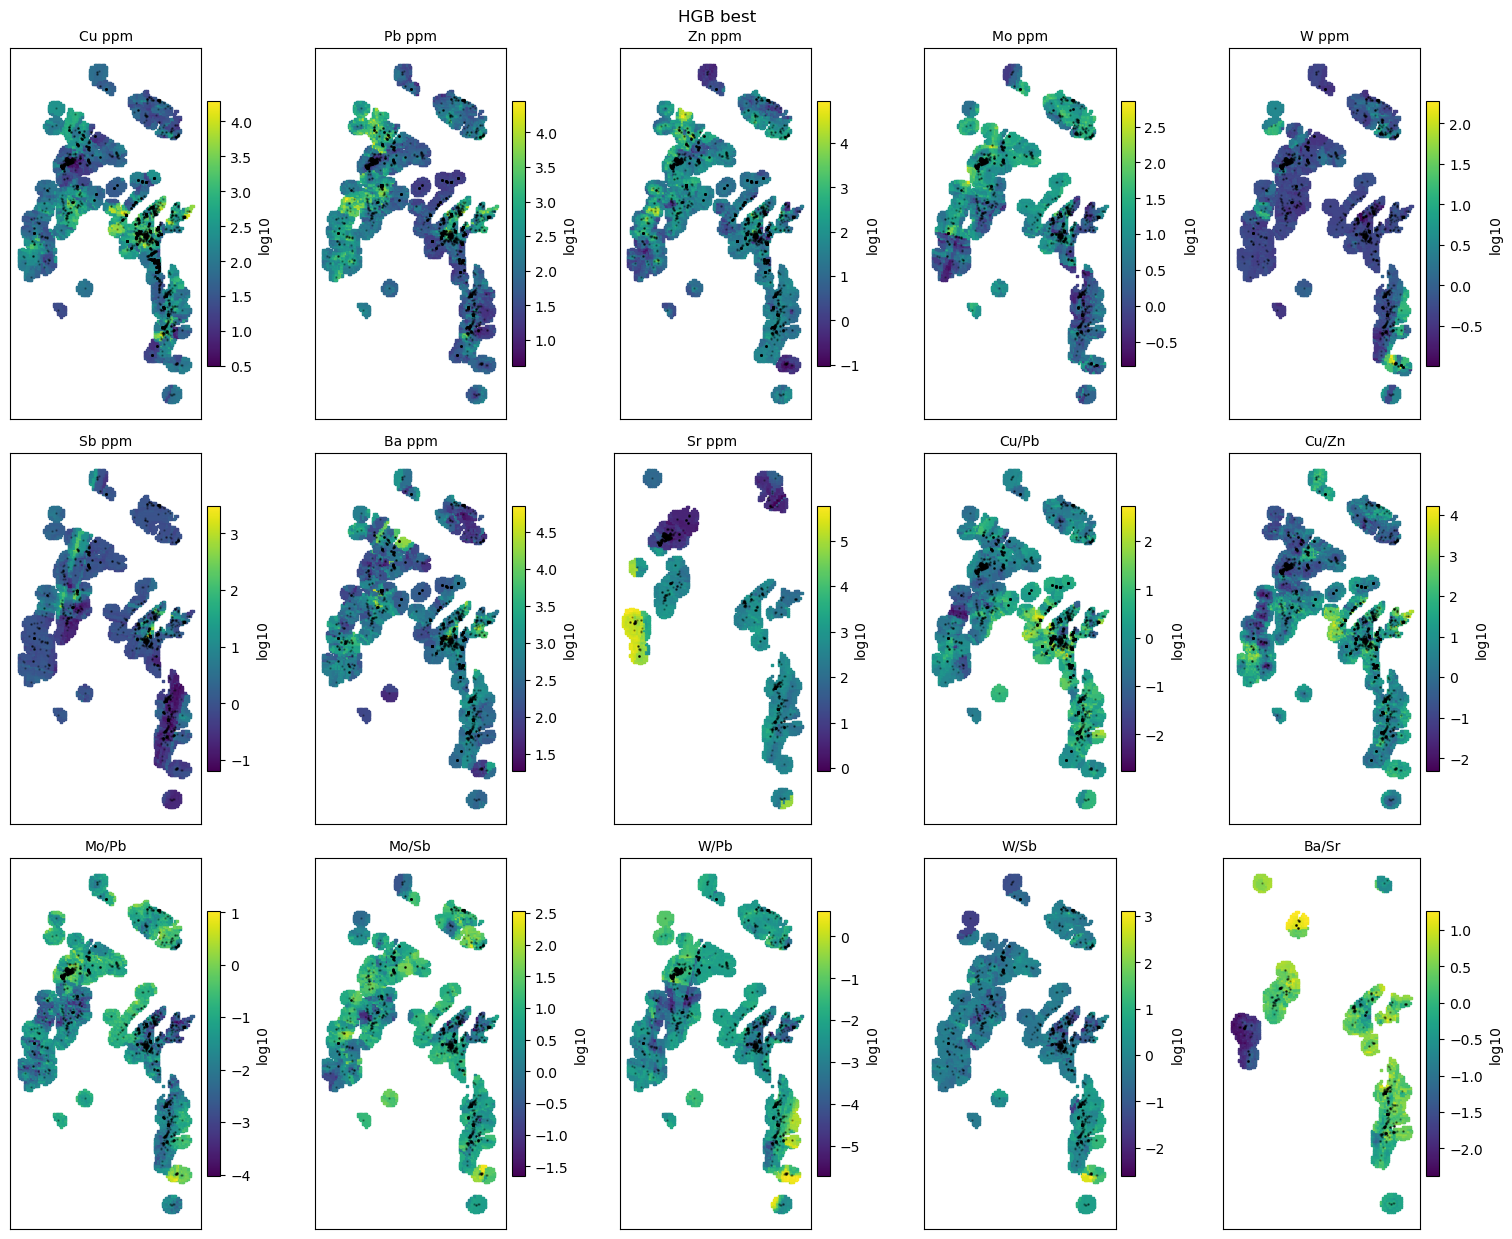

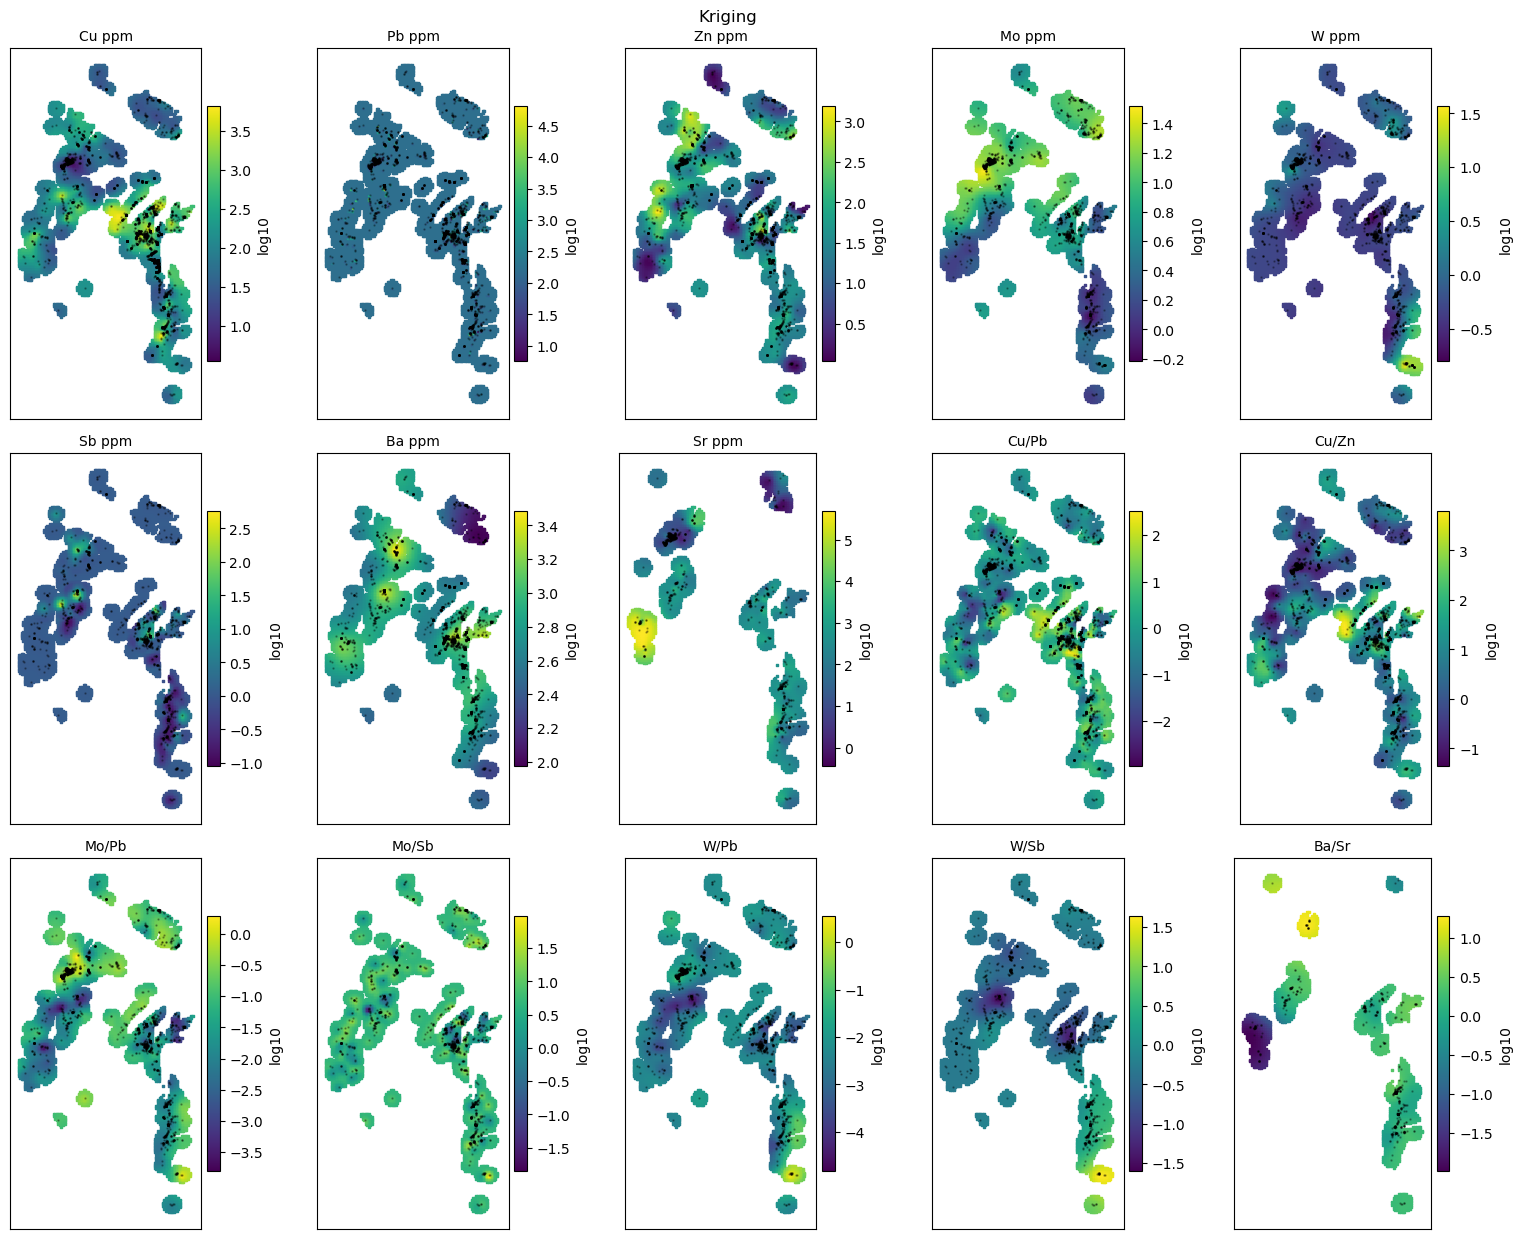

In [126]:
def DisplayMaps(column: str = "", title: str = "HGB, best feature set"):
    cols = 5
    rows = int(np.ceil(len(TARGETS) / cols))
    aspect = 1 / np.cos(np.radians(df["Latitude"].mean()))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 4.2 * rows))

    for ax, target in zip(axes.flat, TARGETS):
        values = grid[f"{target}{column}"].where(grid[f"{target} dist_km"] <= MAX_DISTANCE_KM)
        points = ax.scatter(grid["Longitude"], grid["Latitude"], c=values, s=2, marker="s", cmap="viridis")
        sampled = df[df[target].notna()]
        ax.scatter(sampled["Longitude"], sampled["Latitude"], s=0.5, color="black", alpha=0.3)
        ax.set_aspect(aspect)
        ax.set_title(target, fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(points, ax=ax, fraction=0.046, pad=0.02, label="log10")
    for ax in list(axes.flat)[len(TARGETS):]:
        ax.axis("off")
    fig.suptitle(f"{title}")
    plt.tight_layout()
    plt.show()


DisplayMaps(title="HGB best")
DisplayMaps(" kriging", "Kriging")

### Reading the Results

Against the cached run (10 km blocks, median 2.8 km from a test sample to the nearest training sample):

* **Little spatial signal at map distances.** Under spatial CV the best mean R² is kriging's 0.10. HGB is at or below zero — worse than predicting the mean — because it extrapolates coordinates badly into unseen blocks.
* **Random CV is badly misleading here.** Every method scores ~0.4 under random folds; the drop to spatial CV is 0.3–0.5. Only the spatial numbers apply to a map.
* **Kriging wins most targets** (9/15), IDW 3, HGB 2, GNN 1. The ML models do not beat geostatistics on this task.
* **KNN C (all elements, same 10 neighbours) ≈ the 8-element set** (mean spatial R² −0.024 vs −0.006; better on 9/15 targets). The neighbours' full chemistry adds nothing at map distances.
* **GNNs are the weakest methods** (mean spatial R² −0.23 GAT, −0.35 SAGE; beat kriging on 1/15). With 500–3,600 labelled samples and ~100 input channels they overfit; they are also untuned.
* **The exceptions are clusters, not trends.** Sr (0.63) and Ba/Sr (0.45) are predictable because 27 samples are ~45% Sr (celestine) and 118 are ≥10% Ba (barite), clustered together. W, Mo/Pb and W/Pb carry weaker signal (0.15–0.20).
* **The maps are only as good as those scores.** For most targets they are close to a local average. Read them together with the per-target R², and prefer the kriging column where kriging wins.

Open questions for Pierpaolo: confirm zeros mean below detection (`ZERO_TREATMENT`), and whether the celestine/barite samples belong in a zonation map or should be mapped separately.